# 12 — Optional deterministic CLAHE experiment

## Purpose

This notebook reports the saved **exploratory twelve-epoch** controlled experiment.
Training defaults to disabled. The current B0 recipe is a fixed control, not an
established optimum; results cannot select transformations for other architectures.
Outer fold 0, the reserved test, calibration fitting, uncertainty and fusion are excluded.

C is optional. An unavailable, quality-blocked or unfinished correction experiment has no comparative performance conclusion.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "src/melanoma_detection").is_dir() and (path / "configs/image_model.yaml").is_file())
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.image_conditions import load_config, prepare_conditions, run_conditions
from melanoma_detection.image_condition_reporting import load_condition_outputs, render_condition_report
from melanoma_detection.image_evaluation import sha256

TRAIN_CONDITIONS = False
comparison_label = 'C - A'
config = load_config(PROJECT_ROOT / "configs/image_augmentation.yaml")
run_dir = PROJECT_ROOT / "results/image_d1_runs/b0_lighting_12e_v1"
if TRAIN_CONDITIONS:
    prepared = prepare_conditions(PROJECT_ROOT, config, audit_images=True)
    run_conditions(PROJECT_ROOT, config, prepared=prepared, device="cuda",
        condition_ids=('C',))
summary_path = run_dir / "summary.json"
if summary_path.is_file():
    summary = json.loads(summary_path.read_text(encoding="utf-8"))
else:
    summary = {"run_id": "b0_lighting_12e_v1", "status": "deferred" if True else "not_started",
        "conditions": {}, "reason": "No executed saved condition results; no results fabricated."}
report_conditions = {key: value for key, value in summary.get("conditions", {}).items()
    if key in ('A', 'C')}
bundle = load_condition_outputs(PROJECT_ROOT, {**summary, "conditions": report_conditions})
plt.rcParams.update({"font.size": 10, "figure.facecolor": "white", "axes.facecolor": "white"})
print("Run:", summary["run_id"], "| status:", summary["status"], "| training enabled:", TRAIN_CONDITIONS)
print(summary.get("reason", summary.get("recommendation", "")))
observed_A = summary.get("conditions", {}).get("A", {})
observed_B = summary.get("conditions", {}).get("B", {})
if observed_A.get("status") == "complete":
    display(Markdown("**Executed weak control:** best AP "
        + format(observed_A["best_metrics"]["average_precision"], ".4f")
        + " at epoch " + str(observed_A["best_epoch"])
        + "; epoch-12 AP " + format(observed_A["epoch12_metrics"]["average_precision"], ".4f") + "."))
if observed_B.get("status") == "quality_blocked":
    display(Markdown("**B was not trained:** the predefined stronger profile failed fitting-image quality review. "
        "The A/B comparison is incomplete and no performance winner is declared."))
print("Outer evaluation: not performed | reserved test: not loaded")


Run: b0_lighting_12e_v1 | status: deferred | training enabled: False
CLAHE was not admitted: the required complete safe A/B comparison is unavailable because B failed image-quality review. No dependency installation, correction previews or C training were performed.


**Executed weak control:** best AP 0.1383 at epoch 6; epoch-12 AP 0.1005.

Outer evaluation: not performed | reserved test: not loaded


## Controls and patient isolation

Reuse the saved inner-fold-0 memberships within outer-training folds 1–4:
3,660 fitting images / 225 patients and 1,834 validation images / 113 patients.
Use fresh pretrained B0 initialisation, seed 42, dropout 0.2, square-root fitting-only
positive weighting, backbone LR 3e-5, classifier LR 1e-3, AdamW decay 1e-4,
effective batch 64, frozen BatchNorm and AMP. Every admitted fit executes twelve
epochs without early stopping, including one classifier-only warmup. The fixed
scheduler horizon remains thirty epochs. The highest-AP checkpoint is selected;
exact AP ties retain the earlier epoch. The selected epoch differs from the cap.

Ordinary validation is deterministic. Excluded labels are not used for preparation,
quality previews, weighting, initialisation or prediction. The shared runner owns
training, manifests, compatible epoch-boundary resume and budget enforcement.


In [2]:
ledger = pd.DataFrame([{key: record.get(key) for key in ["condition_id", "pipeline_id", "status",
    "completed_epochs", "best_epoch", "initial_model_state_sha256"]} for record in bundle["records"]])
if not ledger.empty:
    display(ledger)
else:
    print("No admitted saved fits. No learning or prediction results fabricated.")
print("Execution budget: 120 minutes total; training cutoff: minute 100; reporting reserve: 20 minutes")
if summary.get("runtime_estimates"):
    display(pd.DataFrame(summary["runtime_estimates"]).T)


,condition_id,pipeline_id,status,completed_epochs,best_epoch,initial_model_state_sha256
0,A,A_weak_none,complete,12,6.0,322a8f6bdb68d53ae444975c525389e9d75ade0e7b73e3...
1,C,C_weak_clahe,deferred,0,NaN,NaN


Execution budget: 120 minutes total; training cutoff: minute 100; reporting reserve: 20 minutes


## Fitting-only lighting quality inspection

C uses weak augmentation after deterministic CLAHE on CIELAB lightness only,
clip limit 2 and an 8×8 tile grid. This correction is applied identically before
training augmentation and prediction. Random brightness/contrast augmentation
belongs to B and is a different operation. Original image files are preserved.

The same 24 fitting patients used for A/B are inspected as original/corrected
pairs. Any lost lesion boundary, texture or pigmentation, or implausible colour,
blocks C. Admission additionally requires complete A/B fits, passed numerical
checks and sufficient remaining time. Admission never depends on A/B AP.


In [3]:
quality_path = run_dir / "quality_review.json"
if quality_path.is_file():
    quality = json.loads(quality_path.read_text(encoding="utf-8"))
    print("Reviewer:", quality.get("reviewed_by"), "| time:", quality.get("reviewed_at_utc"))
    print("Gate:", {key: value.get("verdict") for key, value in quality.get("conditions", {}).items()})
    display(pd.DataFrame(quality.get("selected_examples", []))[["image_id", "patient_id", "target"]])
    print("Sample coverage:", quality.get("sample_coverage"))
    flagged_reviews = []
    for condition_id, condition in quality.get("conditions", {}).items():
        for review in condition.get("reviews", []):
            if any(isinstance(review.get(name), int) and review[name] >= 2 for name in
                   ["clipping", "boundary", "texture", "colour", "reflection"]):
                flagged_reviews.append({"condition_id": condition_id, **review})
    if flagged_reviews:
        display(Markdown("**Recorded quality failures — these conditions cannot train.**"))
        display(pd.DataFrame(flagged_reviews))
else:
    print("Quality review unavailable; this notebook does not approve it.")
preview_paths = sorted((run_dir / "quality_previews").glob("clahe_pairs_*.png"))
for path in preview_paths:
    display(DisplayImage(filename=str(path)))
if not preview_paths:
    print("No executed preview pages saved for this condition.")


Quality review unavailable; this notebook does not approve it.
No executed preview pages saved for this condition.


## Executed learning and prediction results

Curves use committed epochs only. Hollow rings mark each highest-AP epoch.
Fitting BCE uses the same square-root positive weighting in this experiment;
validation log loss and Brier are unweighted. Historical differently weighted
training losses are not compared as equivalent objectives.

AP is primary. ROC-AUC, actual ROC/precision–recall curves, log loss, Brier and
raw reliability describe additional behaviour. Best-checkpoint and epoch-12
predictions are reported separately on exactly matching validation patients.


### Measured training resources

,pipeline_id,measured_training_minutes,peak_allocated_GiB,committed_epochs
0,A_weak_none,6.96349,2.813129,12


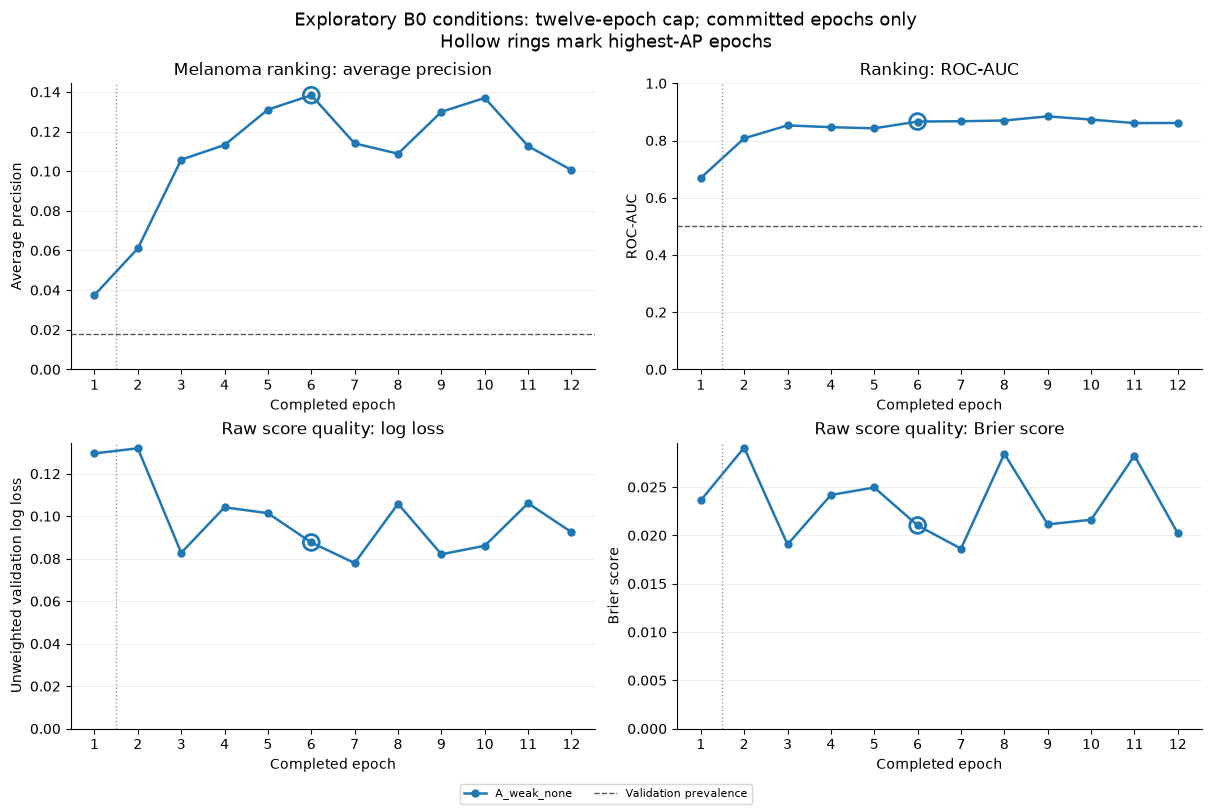

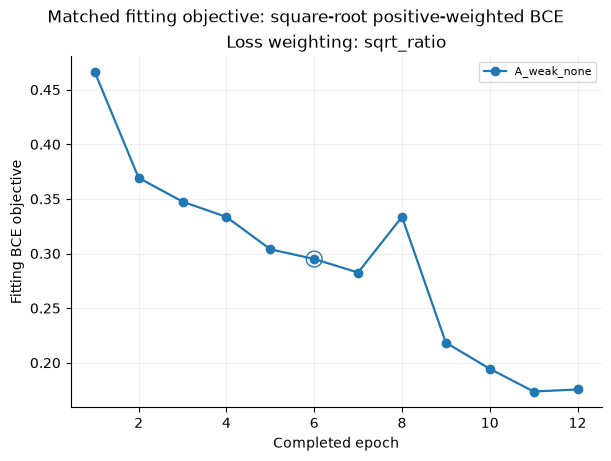

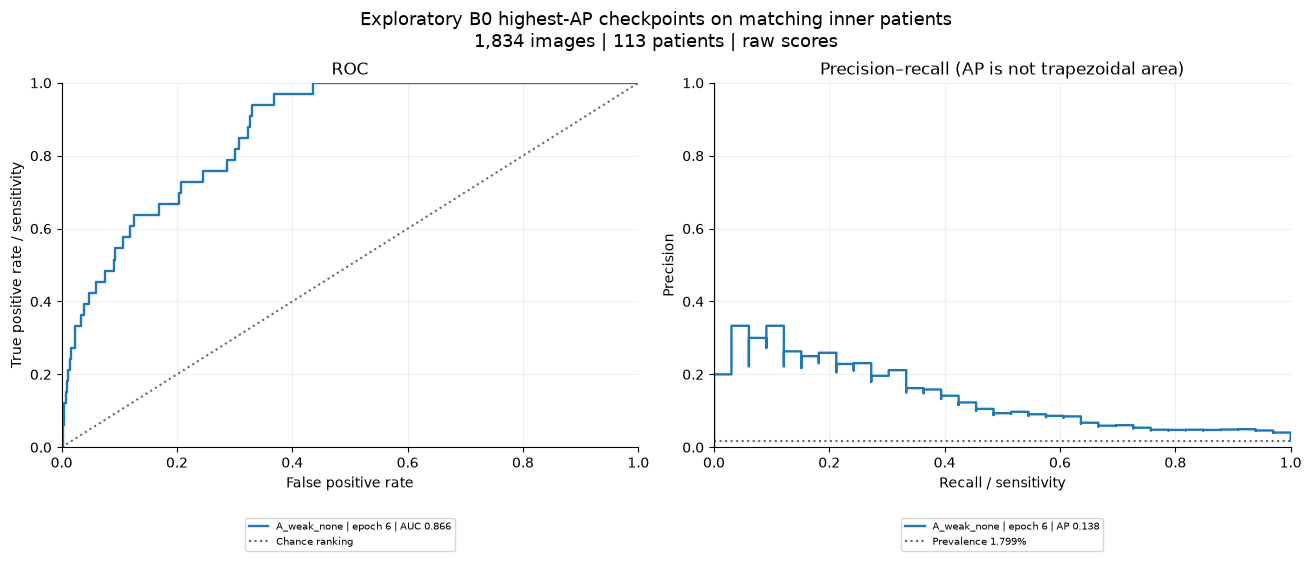

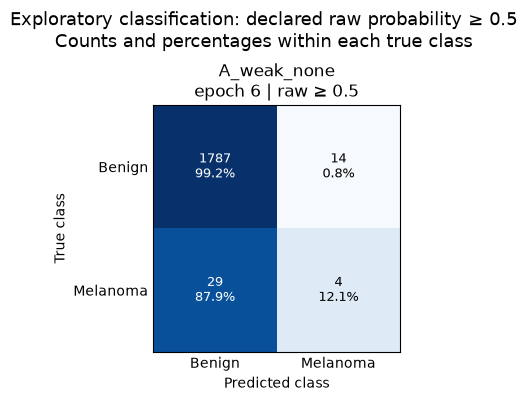

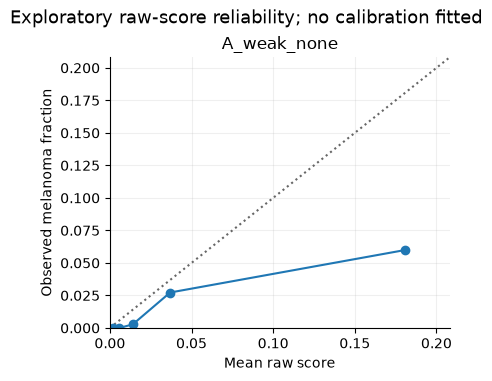

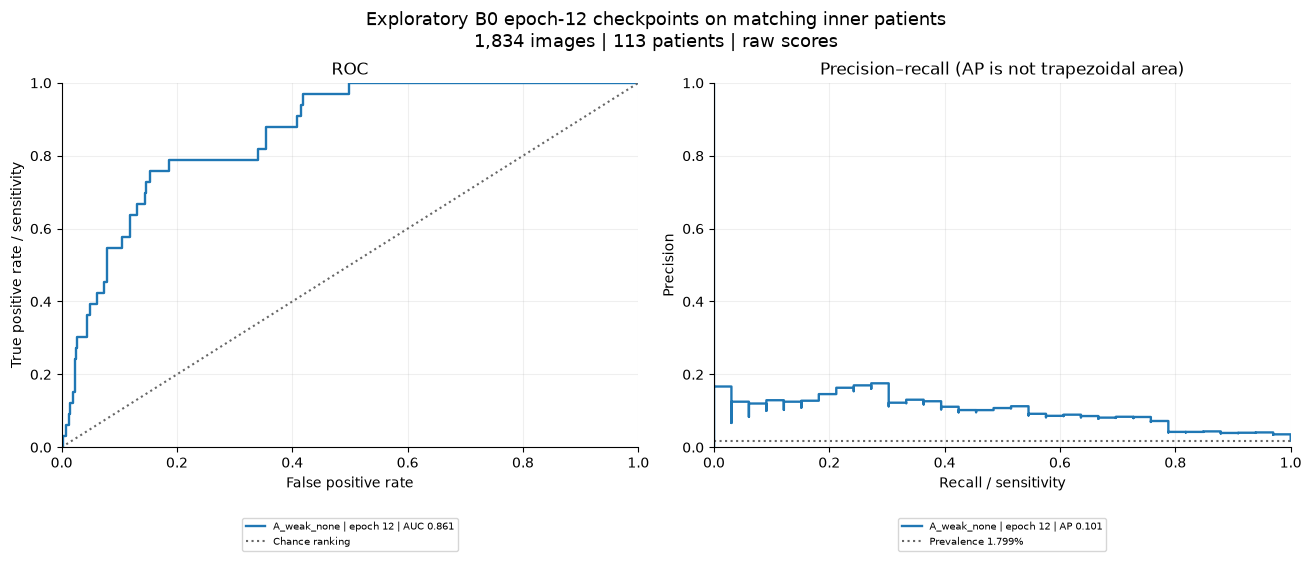

### Highest-AP checkpoints

,pipeline_id,selected_epoch,n_images,n_patients,n_melanoma,average_precision,roc_auc,log_loss,brier
0,A_weak_none,6,1834,113,33,0.1383,0.8663,0.0876,0.0210


### Epoch-12 checkpoints

,pipeline_id,selected_epoch,n_images,n_patients,n_melanoma,average_precision,roc_auc,log_loss,brier
0,A_weak_none,12,1834,113,33,0.1005,0.8613,0.0925,0.0202


In [4]:
report = render_condition_report(bundle, run_dir)
if not report["resources"].empty:
    display(Markdown("### Measured training resources"))
    display(report["resources"])
for figure in report["figures"]:
    display(figure)
    plt.close(figure)
for name, table in [("Highest-AP checkpoints", report["metrics"]),
                    ("Epoch-12 checkpoints", report["epoch12_metrics"])]:
    display(Markdown("### " + name))
    if table.empty:
        print("No complete twelve-epoch records available.")
    else:
        display(table[["pipeline_id", "selected_epoch", "n_images", "n_patients", "n_melanoma",
            "average_precision", "roc_auc", "log_loss", "brier"]].style.format(
            {name: "{:.4f}" for name in ["average_precision", "roc_auc", "log_loss", "brier"]}))


## Threshold-labelled classification

Report F1, precision, recall/sensitivity, specificity and confusion counts at the
declared **raw score ≥0.5** threshold. This threshold is fixed rather than tuned
using validation labels. Undefined precision remains missing. Reliability plots
are descriptive raw-score checks; no calibration model is fitted.

The later academic 80%-recall scenario and any tuned threshold require
training-only OOF predictions. They are not estimated in this experiment.


In [5]:
if not report["metrics"].empty:
    display(report["metrics"][["pipeline_id", "selected_epoch", "threshold", "score_type",
        "TP", "FP", "TN", "FN", "precision", "recall", "sensitivity", "specificity", "f1"]]
        .style.format({name: "{:.4f}" for name in
            ["precision", "recall", "sensitivity", "specificity", "f1"]}, na_rep="Undefined"))
else:
    print("No complete prediction records available for classification reporting.")


,pipeline_id,selected_epoch,threshold,score_type,TP,FP,TN,FN,precision,recall,sensitivity,specificity,f1
0,A_weak_none,6,0.500000,raw_base_probability,4,14,1787,29,0.2222,0.1212,0.1212,0.9922,0.1569


## Exploratory comparisons and next steps

Compare B against fresh A and optional C against fresh A only after both sides
complete the identical twelve-epoch horizon. A safety-passing AP gain ≥0.005 is
a promising **B0 hypothesis**, not statistical proof, a clinical result or an
established optimum. Smaller gains retain weak/unchanged as the development
reference; they do not globally remove candidates for DenseNet or ConvNeXt.

Paused or quality-blocked conditions cannot be classified as inferior. Preserve
compatible checkpoints and complete the matching horizons before drawing a
comparison. Stronger+CLAHE combinations require both individual safety and AP
gates, a later matched experiment and improvement over the better individual.


In [6]:
display(report["comparisons"].loc[report["comparisons"].comparison.eq(comparison_label)])
completed = [row for row in bundle["records"] if row.get("status") == "complete"]
if completed:
    late = [row["condition_id"] for row in completed if row.get("best_epoch", 0) >= 10]
    if late:
        print("Highest-AP epochs near the twelve-epoch cap:", ", ".join(late),
            "— further training is a later validation question.")
    else:
        print("Highest-AP checkpoints precede the cap. Increasing the epoch budget alone is not supported by this split; "
            "confirm duration across three patient-grouped inner folds with the later stopping rules.")
receipt = {"run_id": summary["run_id"], "training_enabled_in_notebook": TRAIN_CONDITIONS,
    "status": summary["status"], "threshold": .5, "threshold_tuned": False,
    "calibration_fitted": False, "reserved_test_loaded": False, "outer_evaluation": False,
    "reporting_source_sha256": {relative: sha256(PROJECT_ROOT / relative) for relative in [
        "src/melanoma_detection/image_condition_reporting.py", "scripts/build_image_condition_notebooks.py"]},
    "summary_sha256": sha256(summary_path) if summary_path.is_file() else None,
    "quality_review_sha256": sha256(quality_path) if quality_path.is_file() else None,
    "figures": [str(path.relative_to(run_dir)) for path in report["figure_paths"]],
    "figure_sha256": {str(path.relative_to(run_dir)): sha256(path) for path in report["figure_paths"]},
    "prediction_csv_sha256": {record[key]: sha256(Path(record[key]) if Path(record[key]).is_absolute()
        else PROJECT_ROOT / record[key]) for record in bundle["records"] if record.get("status") == "complete"
        for key in ["predictions_file", "epoch12_predictions_file"] if record.get(key)}}
run_dir.mkdir(parents=True, exist_ok=True)
(run_dir / "reporting_receipt.json").write_text(json.dumps(receipt, indent=2), encoding="utf-8")
print("Saved outputs:", run_dir)
print("No optimal transformation claimed | no final architecture selected")


,comparison,status,ap_delta,screening_margin,promising_b0_hypothesis,interpretation
1,C - A,incomplete,NaN,0.005,False,Unequal or unavailable twelve-epoch results ca...


Highest-AP checkpoints precede the cap. Increasing the epoch budget alone is not supported by this split; confirm duration across three patient-grouped inner folds with the later stopping rules.
Saved outputs: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\results\image_d1_runs\b0_lighting_12e_v1
No optimal transformation claimed | no final architecture selected


## Deferred roadmap

Hair removal, combinations, longer training and three-inner-fold confirmation
remain separate. DenseNet121 and ConvNeXt-Tiny must independently screen their
training recipes, augmentation and safe preprocessing. Swin eligibility depends
on resources before final evaluation. Every selection choice repeats inside
each outer-training partition under a frozen bounded procedure.

Nested outer evaluation, OOF calibration/threshold fitting, patient-bootstrap
intervals, uncertainty, fusion and the single reserved-test evaluation are deferred.
Exploratory results cannot globally prune the final candidate library or choose
a final model from the best-performing outer fold.


## Limitations

This is one exploratory inner patient split, with 33 positive validation images.
The B0 control and highest-AP epoch were selected during development; these
scores are not nested outer-fold evidence. A blocked or deferred condition has
no comparative performance result. The sampled quality review cannot certify
every image. Raw threshold 0.5 is an explicit reporting scenario, not a tuned
clinical operating point, and the raw reliability plot does not fit calibration.
No setting is established as optimal, and B0 findings cannot select another
architecture's transformations or training duration.

## Summary


In [7]:
if observed_A.get("status") == "complete":
    print("Fresh weak B0 control: twelve epochs complete; highest AP",
        format(observed_A["best_metrics"]["average_precision"], ".4f"),
        "at epoch", observed_A["best_epoch"], "; epoch-12 AP",
        format(observed_A["epoch12_metrics"]["average_precision"], ".4f"))
comparison = report["comparisons"].loc[report["comparisons"].comparison.eq(comparison_label)]
display(comparison)
if summary.get("status") in ("incomplete", "deferred"):
    print("No comparative advancement decision. Preserve weak/unchanged as the development reference.")
print("Next: declare and inspect a safer augmentation profile, then complete a fresh matched comparison. "
    "CLAHE still requires its admission gate; longer confirmation and architecture-specific selection remain later stages.")


Fresh weak B0 control: twelve epochs complete; highest AP 0.1383 at epoch 6 ; epoch-12 AP 0.1005


,comparison,status,ap_delta,screening_margin,promising_b0_hypothesis,interpretation
1,C - A,incomplete,NaN,0.005,False,Unequal or unavailable twelve-epoch results ca...


No comparative advancement decision. Preserve weak/unchanged as the development reference.
Next: declare and inspect a safer augmentation profile, then complete a fresh matched comparison. CLAHE still requires its admission gate; longer confirmation and architecture-specific selection remain later stages.
